<a href="https://colab.research.google.com/github/JaafarBK02/satellite-cnn-vit/blob/main/04_baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os, sys, numpy as np, torch, torchvision
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# --- Drive (cache lives here) ---
from google.colab import drive
drive.mount('/content/drive')
CACHE = '/content/drive/MyDrive/tile2vec_data/features.npz'

# --- Repo, tiles, checkpoint: only fetched if missing ---
if not os.path.exists('tile2vec'):
    !git clone -q https://github.com/ermongroup/tile2vec.git
if not os.path.exists('tile2vec/data/tiles/1tile.npy'):
    !cd tile2vec/data && unzip -nq tiles.zip
ckpt = 'tile2vec/models/naip_trained.ckpt'
if not os.path.exists(ckpt) or os.path.getsize(ckpt) < 1e6:
    !wget -q -O tile2vec/models/naip_trained.ckpt "https://www.dropbox.com/s/bvzriiqlcof5lol/naip_trained.ckpt?dl=1"

if os.path.exists(CACHE):
    # --- Fast path: load saved features ---
    d = np.load(CACHE)
    X, y, X_raw, X_imagenet = d['X'], d['y'], d['X_raw'], d['X_imagenet']
    print('Loaded cached features from Drive')
else:
    # --- First time: build everything, then save ---
    tiles = np.stack([np.load(f'tile2vec/data/tiles/{i+1}tile.npy') for i in range(1000)])
    y = np.load('tile2vec/data/tiles/y.npy')
    X_raw = tiles[..., :4].reshape(1000, -1) / 255.0

    sys.path.append('tile2vec')
    from src.tilenet import make_tilenet
    tilenet = make_tilenet(in_channels=4, z_dim=512)
    tilenet.load_state_dict(torch.load(ckpt, map_location=device), strict=False)
    tilenet.to(device).eval()
    t4 = torch.from_numpy(np.moveaxis(tiles[..., :4].astype(np.float32), -1, 1) / 255.0)
    with torch.no_grad():
        X = np.concatenate([tilenet.encode(t4[b:b+100].to(device)).cpu().numpy() for b in range(0, 1000, 100)])

    resnet = torchvision.models.resnet18(weights='IMAGENET1K_V1')
    resnet.fc = torch.nn.Identity()
    resnet = resnet.to(device).eval()
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    rgb = t4[:, :3]
    with torch.no_grad():
        X_imagenet = np.concatenate([
            resnet((F.interpolate(rgb[b:b+100].to(device), size=224, mode='bilinear', align_corners=False) - mean) / std).cpu().numpy()
            for b in range(0, 1000, 100)])

    np.savez(CACHE, X=X, y=y, X_raw=X_raw, X_imagenet=X_imagenet)
    print('Built features and saved to Drive')

# --- Evaluation helpers ---
def evaluate_trials(X, y, make_model, n_trials=100, n_train=None):
    accs, f1s = [], []
    for i in range(n_trials):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=i)
        if n_train is not None:
            X_tr, y_tr = X_tr[:n_train], y_tr[:n_train]
        p = make_model(i).fit(X_tr, y_tr).predict(X_te)
        accs.append(accuracy_score(y_te, p))
        f1s.append(f1_score(y_te, p, average='macro', zero_division=0))
    return np.array(accs), np.array(f1s)

rf     = lambda i: RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=i)
lr     = lambda i: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
pca_rf = lambda i: make_pipeline(PCA(10, random_state=i), rf(i))
pca_lr = lambda i: make_pipeline(PCA(10, random_state=i), StandardScaler(), LogisticRegression(max_iter=2000))
setups = {
    'Tile2Vec (pretrained)':    (X,          rf,     lr),
    'ImageNet ResNet-18 (RGB)': (X_imagenet, rf,     lr),
    'Raw pixels + PCA(10)':     (X_raw,      pca_rf, pca_lr),
}
print('Ready:', X.shape, X_raw.shape, X_imagenet.shape, y.shape)

Mounted at /content/drive
Loaded cached features from Drive
Ready: (1000, 512) (1000, 10000) (1000, 512) (1000,)


In [4]:
results = {}
for name, (Xf, rf_make, lr_make) in setups.items():
    for clf, make in [('RF', rf_make), ('LR', lr_make)]:
        a, f = evaluate_trials(Xf, y, make, n_trials=100)
        results[(name, clf)] = (a, f)
        print(f'{name:26s} {clf}: accuracy {a.mean():.4f} ± {a.std():.4f} | macro F1 {f.mean():.3f}')

# PCA with 50 components (random forest)
pca50_rf = lambda i: make_pipeline(PCA(50, random_state=i), rf(i))
a, f = evaluate_trials(X_raw, y, pca50_rf, n_trials=100)
print(f'{"Raw pixels + PCA(50)":26s} RF: accuracy {a.mean():.4f} ± {a.std():.4f} | macro F1 {f.mean():.3f}')

# Majority baseline: always predict the most common class (grapes, 69)
maj = [np.mean(train_test_split(X, y, test_size=0.2, random_state=i)[3] == 69) for i in range(100)]
print(f'Always "grapes" (class 69): accuracy {np.mean(maj):.3f}')

Tile2Vec (pretrained)      RF: accuracy 0.7174 ± 0.0272 | macro F1 0.393
Tile2Vec (pretrained)      LR: accuracy 0.7025 ± 0.0277 | macro F1 0.410
ImageNet ResNet-18 (RGB)   RF: accuracy 0.6852 ± 0.0312 | macro F1 0.227
ImageNet ResNet-18 (RGB)   LR: accuracy 0.6854 ± 0.0308 | macro F1 0.351
Raw pixels + PCA(10)       RF: accuracy 0.6233 ± 0.0321 | macro F1 0.247
Raw pixels + PCA(10)       LR: accuracy 0.5764 ± 0.0303 | macro F1 0.165
Raw pixels + PCA(50)       RF: accuracy 0.6216 ± 0.0341 | macro F1 0.219
Always "grapes" (class 69): accuracy 0.358


In [5]:
for clf in ['RF', 'LR']:
    a_t2v = results[('Tile2Vec (pretrained)', clf)][0]
    a_imn = results[('ImageNet ResNet-18 (RGB)', clf)][0]
    print(f'{clf}: Tile2Vec better on {np.mean(a_t2v > a_imn):.0%} of splits | '
          f'mean gain {np.mean(a_t2v - a_imn):+.4f} | Wilcoxon p = {wilcoxon(a_t2v, a_imn).pvalue:.1e}')

RF: Tile2Vec better on 89% of splits | mean gain +0.0323 | Wilcoxon p = 6.8e-16
LR: Tile2Vec better on 69% of splits | mean gain +0.0171 | Wilcoxon p = 2.6e-07


Tile2Vec (pretrained) 50:0.542 100:0.604 200:0.650 400:0.686 800:0.727
ImageNet ResNet-18 (RGB) 50:0.571 100:0.618 200:0.646 400:0.669 800:0.689
Raw pixels + PCA(10) 50:0.464 100:0.508 200:0.551 400:0.595 800:0.631


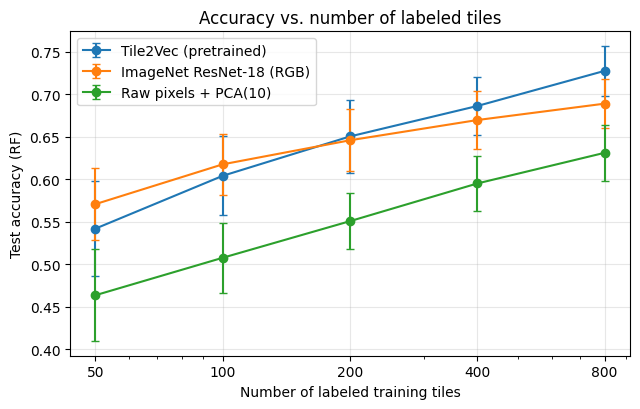

In [6]:
N_LIST = [50, 100, 200, 400, 800]
curve = {}
for name, (Xf, rf_make, _) in setups.items():
    means, sds = [], []
    for n in N_LIST:
        a, _ = evaluate_trials(Xf, y, rf_make, n_trials=20, n_train=n)
        means.append(a.mean()); sds.append(a.std())
    curve[name] = (means, sds)
    print(name, ' '.join(f'{n}:{m:.3f}' for n, m in zip(N_LIST, means)))

plt.figure(figsize=(6.5, 4.2))
for name, (m, s) in curve.items():
    plt.errorbar(N_LIST, m, yerr=s, marker='o', capsize=3, label=name)
plt.xscale('log'); plt.xticks(N_LIST, N_LIST)
plt.xlabel('Number of labeled training tiles'); plt.ylabel('Test accuracy (RF)')
plt.title('Accuracy vs. number of labeled tiles'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('label_curve.png', dpi=150); plt.show()